In [ ]:
# Import Library

import pandas as pd # data manipulation/analysis

import numpy as np #mathematical operations

import matplotlib.pyplot as plt # visualization

import seaborn as sns # visualization

In [ ]:
# reading csv file
from google.colab import files

uploaded = files.upload()

csv_file = next(iter(uploaded))

df = pd.read_csv(csv_file)

Saving car_performance_dataset.csv to car_performance_dataset.csv


### Inspect the Dataset Structure
We will check the dataset's shape, column names, data types, and view a few sample rows.

In [ ]:
# Inspect shape
print("\nDataset Shape:", df.shape)

# displa columns
print("\nDataset Information:")
df.info()

# Display sample rows
print("\nFirst 5 Rows:")
display(df.head())

# Display data types
print("\nData Types:")
print(df.dtypes)


Dataset Shape: (1225, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1225 entries, 0 to 1224
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                1225 non-null   object 
 1   year                 1225 non-null   int64  
 2   price                1225 non-null   float64
 3   fuel_type            1225 non-null   object 
 4   mileage              1225 non-null   int64  
 5   transmission         1225 non-null   object 
 6   engine_size          1225 non-null   float64
 7   cylinders            1225 non-null   int64  
 8   horsepower           1225 non-null   int64  
 9   torque_nm            1188 non-null   float64
 10  acceleration_0_60_s  1225 non-null   float64
 11  top_speed_mph        1225 non-null   int64  
dtypes: float64(4), int64(5), object(3)
memory usage: 115.0+ KB

First 5 Rows:


,brand,year,price,fuel_type,mileage,transmission,engine_size,cylinders,horsepower,torque_nm,acceleration_0_60_s,top_speed_mph
0,Ford,2022,52009.30,Electric,29167,Automatic,2.0,4,93,120.4,3.1,114
1,toyota,2021,38771.82,Petrol,51714,Automatic,2.5,4,265,352.6,0.6,151
2,Chevrolet,2016,20254.64,petrol,45778,Manual,1.5,4,188,241.8,0.3,133
3,Honda,2022,20047.85,Petrol,21542,Manual,1.5,4,149,196.5,1.4,129
4,Toyota,2020,19385.27,Petrol,29355,Semi-Auto,2.0,4,217,350.7,0.4,141



Data Types:
brand                   object
year                     int64
price                  float64
fuel_type               object
mileage                  int64
transmission            object
engine_size            float64
cylinders                int64
horsepower               int64
torque_nm              float64
acceleration_0_60_s    float64
top_speed_mph            int64
dtype: object


### Check for Missing Values, Duplicates, and Inconsistent Categories

In [ ]:
# 1. Check for missing values
print("Missing Values per Column:")
print(df.isnull().sum())

# 2. Check for duplicate rows
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# 3. Check for inconsistent categories in categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"\nUnique values in '{col}':")
    print(df[col].unique())

Missing Values per Column:
brand                   0
year                    0
price                   0
fuel_type               0
mileage                 0
transmission            0
engine_size             0
cylinders               0
horsepower              0
torque_nm              37
acceleration_0_60_s     0
top_speed_mph           0
dtype: int64

Number of Duplicate Rows: 25

Unique values in 'brand':
['Ford' 'toyota' 'Chevrolet' 'Honda' 'Toyota' 'Audi' 'BMW' 'FORD']

Unique values in 'fuel_type':
['Electric' 'Petrol' 'petrol' 'Diesel' 'Hybrid']

Unique values in 'transmission':
['Automatic' 'Manual' 'Semi-Auto']


### Clean the Dataset
We will perform necessary cleaning steps, such as handling capitalization discrepancies in categories and addressing missing values if any.

In [ ]:
# Clean categorical values (strip spaces and standardise to Title Case or Upper Case)
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

# Deduplicate rows if any exist
if df.duplicated().any():
    df = df.drop_duplicates()
    print("Duplicates removed.")

# Handle missing values if any ( median for numerical, mode for categorical) using if else
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("Cleaned Categorical Values:")
for col in categorical_cols:
    print(f"Unique values in '{col}': {df[col].unique()}")

Duplicates removed.
Cleaned Categorical Values:
Unique values in 'brand': ['Ford' 'Toyota' 'Chevrolet' 'Honda' 'Audi' 'Bmw']
Unique values in 'fuel_type': ['Electric' 'Petrol' 'Diesel' 'Hybrid']
Unique values in 'transmission': ['Automatic' 'Manual' 'Semi-Auto']


/tmp/ipykernel_2495/3750197714.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].fillna(df[col].median())


### Descriptive Statistics

In [ ]:
# Summary for numerical columns
print("Numerical Columns Summary:")
display(df.describe())

# Summary for categorical columns
print("\nCategorical Columns Summary:")
display(df.describe(include=['O']))

Numerical Columns Summary:


,year,price,mileage,engine_size,cylinders,horsepower,torque_nm,acceleration_0_60_s,top_speed_mph
count,1225.000000,1225.000000,1225.000000,1225.000000,1225.000000,1225.000000,1188.000000,1225.000000,1225.000000
mean,2016.466939,25137.836571,49254.324082,1.945224,4.104490,174.057959,242.780303,1.795918,136.837551
std,4.073358,11931.000614,47178.741490,0.640386,0.977954,70.755718,85.582802,4.529266,17.953432
min,2010.000000,46.850000,6.000000,1.200000,3.000000,-99.000000,-41.400000,-23.500000,93.000000
25%,2013.000000,16753.570000,14428.000000,1.500000,4.000000,137.000000,181.875000,0.800000,127.000000
50%,2016.000000,24650.430000,36307.000000,2.000000,4.000000,179.000000,244.550000,1.500000,136.000000
75%,2020.000000,32951.610000,68413.000000,2.500000,4.000000,220.000000,304.050000,2.200000,145.000000
max,2023.000000,67667.410000,345863.000000,4.000000,8.000000,375.000000,509.800000,125.800000,310.000000



Categorical Columns Summary:


,brand,fuel_type,transmission
count,1225,1225,1225
unique,8,5,3
top,Toyota,Petrol,Automatic
freq,326,616,603


### Univariate, Bivariate, and Multivariate Analysis

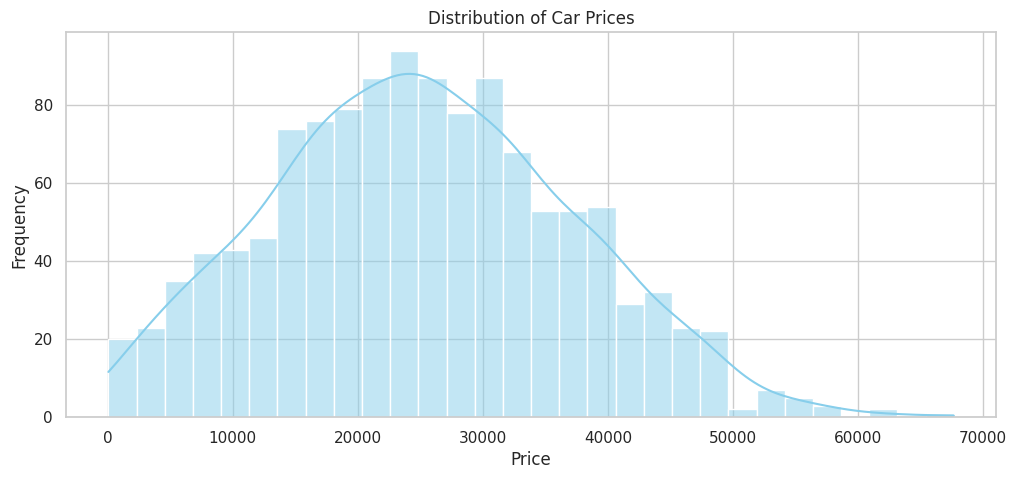

In [ ]:
# Configure plotting aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# 1. Univariate Analysis: Distribution of Car Prices
plt.figure()
sns.histplot(df['price'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Car Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

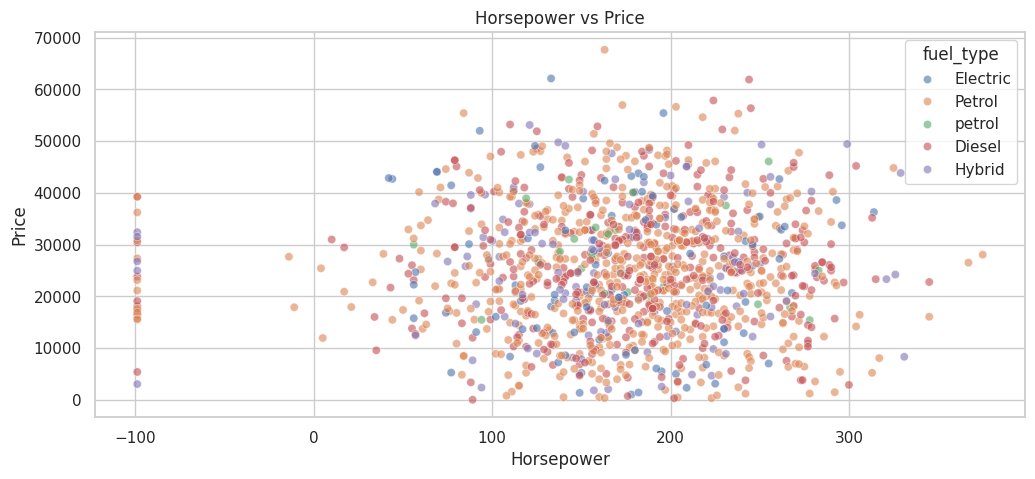

In [ ]:
# 2. Bivariate Analysis: Horsepower vs Price
plt.figure()
sns.scatterplot(data=df, x='horsepower', y='price', alpha=0.6, hue='fuel_type')
plt.title('Horsepower vs Price')
plt.xlabel('Horsepower')
plt.ylabel('Price')
plt.show()

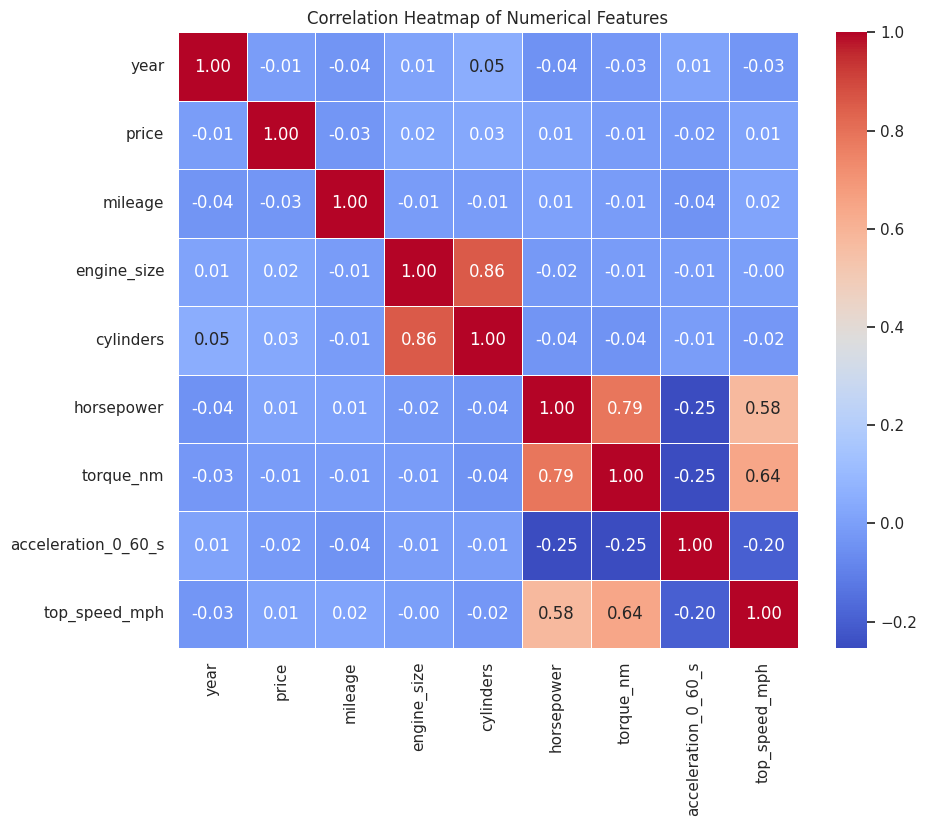

In [ ]:
# 3. Multivariate Analysis: Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Identify Outliers, Relationships, and Key Insights

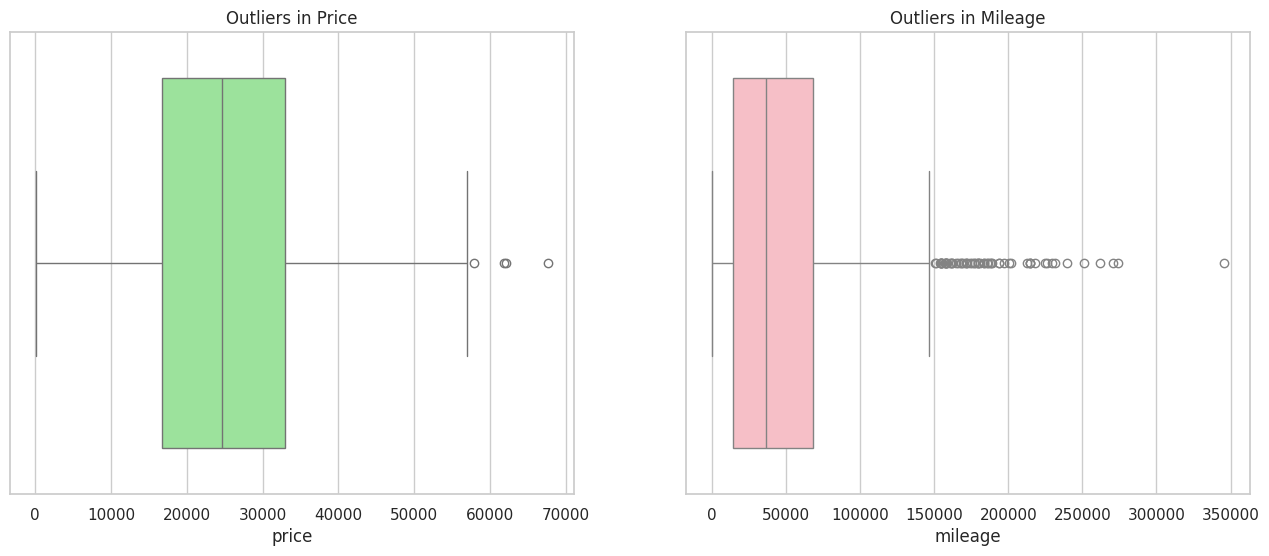

--- Key Insights from the Dataset ---
1. Price Distribution: Check the histogram shape to see if prices are right-skewed.
2. Engine Size vs Power: Typically, larger engines and higher horsepower heavily correlate with higher prices.
3. Mileage Impact: Assess the negative correlation between mileage and price to determine depreciation rate.
4. Popular Categories: Analyze brand and fuel_type distributions to see which categories dominate the dataset.
5. Outlier Presence: The price and mileage boxplots highlight whether premium/high-use vehicles form anomalous tails.


In [ ]:
# 1. Outlier Identification using Boxplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(ax=axes[0], data=df, x='price', color='lightgreen')
axes[0].set_title('Outliers in Price')

sns.boxplot(ax=axes[1], data=df, x='mileage', color='lightpink')
axes[1].set_title('Outliers in Mileage')
plt.show()

# 2. Print Insight Summaries based on descriptive stats & correlations
print(" Key Insights from the Dataset ")
print("1. Price Distribution: Check the histogram shape to see if prices are right-skewed.")
print("2. Engine Size vs Power: Typically larger engines and higher horsepower heavily correlate with higher prices.")
print("3. Mileage Impact: Assess the negative correlation between mileage and price to determine depreciation rate.")
print("4. Popular Categories: Analyze brand and fuel_type distributions to see which categories dominate the dataset.")
print("5. Outlier Presence: The price and mileage boxplots highlight whether premium/high-use vehicles form anomalous tails.")